In [1]:
import os
GPU_ID = "5"  # physical GPU 3 on the DGX host; it will appear as /GPU:0 here
os.environ["CUDA_VISIBLE_DEVICES"] = GPU_ID
os.environ["TF_FORCE_GPU_ALLOW_GROWTH"] = "true"

import glob
import random
import math
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import tensorflow as tf
from pathlib import Path

SEED = 42
IMG_SIZE = (256, 384)  # (height, width); preserves Warwick QU landscape aspect ratio approximately
BATCH_SIZE = 1
EPOCHS = 50
LEARNING_RATE = 3e-4
BOUNDARY_TOLERANCE_PX = 2
PREDICTION_THRESHOLD = 0.5

DATASET_ROOT = "/raid/home/dgx1725/Warwick_QU_Dataset_Binary_FIXED"
TRAIN_IMAGE_DIR = os.path.join(DATASET_ROOT, "train", "img")
TRAIN_MASK_DIR  = os.path.join(DATASET_ROOT, "train", "mask")
VAL_IMAGE_DIR   = os.path.join(DATASET_ROOT, "val", "img")
VAL_MASK_DIR    = os.path.join(DATASET_ROOT, "val", "mask")
TEST_IMAGE_DIR  = os.path.join(DATASET_ROOT, "test", "img")
TEST_MASK_DIR   = os.path.join(DATASET_ROOT, "test", "mask")
# Aliases retained for model/evaluation utility code; training paths are the train split.
IMAGE_DIR = TRAIN_IMAGE_DIR
MASK_DIR = TRAIN_MASK_DIR
OUTPUT_DIR = "/raid/home/dgx1725/warwick_qu_resunet_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

for directory in [TRAIN_IMAGE_DIR, TRAIN_MASK_DIR, VAL_IMAGE_DIR, VAL_MASK_DIR, TEST_IMAGE_DIR, TEST_MASK_DIR]:
    if not os.path.isdir(directory):
        raise FileNotFoundError(f"Required Warwick QU dataset directory does not exist: {directory}")

print("Dataset root:", DATASET_ROOT)
print("Image/mask directories:")
for split in ("train", "val", "test"):
    im_dir = os.path.join(DATASET_ROOT, split, "img")
    ma_dir = os.path.join(DATASET_ROOT, split, "mask")
    print(f"  {split}: images={len([p for p in Path(im_dir).iterdir() if p.is_file()])}, masks={len([p for p in Path(ma_dir).iterdir() if p.is_file()])}")
print("Output directory:", OUTPUT_DIR)

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Configure memory growth before any GPU operation initializes the device.
physical_gpus = tf.config.list_physical_devices("GPU")
print("Visible TensorFlow GPUs:", physical_gpus)
for gpu in physical_gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as exc:
        print("Could not set memory growth (GPU may already be initialized):", exc)

if physical_gpus:
    try:
        with tf.device("/GPU:0"):
            _a = tf.random.uniform((256, 256))
            _b = tf.random.uniform((256, 256))
            _test = tf.linalg.matmul(_a, _b)
            _ = _test.numpy()
        print("GPU matrix-operation test: PASS")
    except Exception as exc:
        raise RuntimeError(
            "GPU was detected, but the GPU matrix-operation test failed. "
            "Restart Jupyter from the DGX terminal using the LD_LIBRARY_PATH command in the first markdown cell, "
            "then restart this notebook kernel. Also check free memory with nvidia-smi."
        ) from exc
else:
    print("WARNING: TensorFlow sees no GPU; training will run on CPU unless the environment is fixed.")

print("TensorFlow version:", tf.__version__)

2026-10-20 02:24:56.263565: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-10-20 02:24:56.263615: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-20 02:24:56.264914: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-10-20 02:24:56.273741: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-10-20 02:24:57.229150: W tensorflow/compiler/tf2

Dataset root: /raid/home/dgx1725/Warwick_QU_Dataset_Binary_FIXED
Image/mask directories:
  train: images=133, masks=133
  val: images=16, masks=16
  test: images=16, masks=16
Output directory: /raid/home/dgx1725/warwick_qu_resunet_outputs
Visible TensorFlow GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


2026-10-20 02:25:00.289883: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1929] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 30953 MB memory:  -> device: 0, name: Tesla V100-SXM2-32GB, pci bus id: 0000:86:00.0, compute capability: 7.0


GPU matrix-operation test: PASS
TensorFlow version: 2.15.1


[train] images=133, masks=133, pairs=133
[val] images=16, masks=16, pairs=16
[test] images=16, masks=16, pairs=16

Dataset pairs — train: 133, validation: 16, test: 16


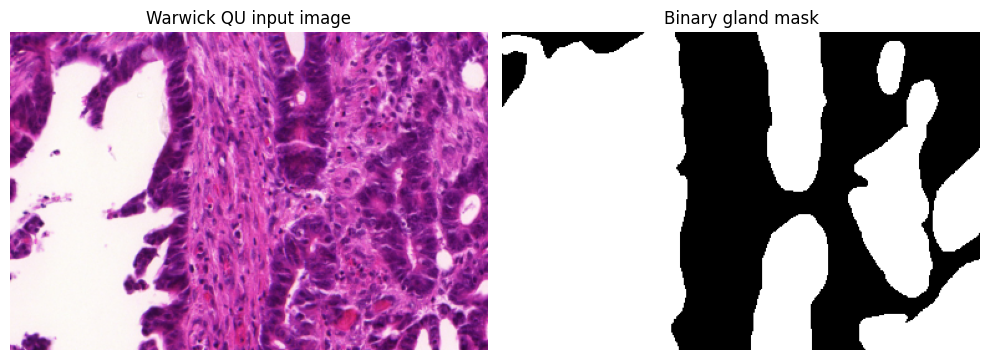

In [2]:
VALID_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp", ".bm", ".tif", ".tiff")

def list_image_files(directory):
    directory = Path(directory)
    if not directory.is_dir():
        raise FileNotFoundError(f"Image/mask directory not found: {directory}")
    return sorted(
        str(p) for p in directory.iterdir()
        if p.is_file() and p.suffix.lower() in VALID_EXTENSIONS
    )

def normalized_mask_stem(path):
    stem = Path(path).stem
    # Warwick QU masks commonly append `_anno` to the image stem.
    if stem.lower().endswith("_anno"):
        stem = stem[:-5]
    return stem

def get_pairs(image_dir, mask_dir, split_name):
    image_paths = list_image_files(image_dir)
    mask_paths = list_image_files(mask_dir)

    mask_map = {}
    duplicates = []
    for mask_path in mask_paths:
        key = normalized_mask_stem(mask_path)
        if key in mask_map:
            duplicates.append((key, mask_map[key], mask_path))
        else:
            mask_map[key] = mask_path
    if duplicates:
        raise RuntimeError(f"Duplicate normalized mask stems in {mask_dir}: {duplicates[:5]}")

    pairs, unmatched_images = [], []
    matched_stems = set()
    for image_path in image_paths:
        stem = Path(image_path).stem
        mask_path = mask_map.get(stem)
        if mask_path is None:
            unmatched_images.append(image_path)
        else:
            pairs.append((image_path, mask_path))
            matched_stems.add(stem)

    unmatched_masks = sorted(set(mask_map) - matched_stems)
    print(f"[{split_name}] images={len(image_paths)}, masks={len(mask_paths)}, pairs={len(pairs)}")
    if unmatched_images:
        print(f"WARNING [{split_name}]: {len(unmatched_images)} images have no mask. Examples:", unmatched_images[:5])
    if unmatched_masks:
        print(f"WARNING [{split_name}]: {len(unmatched_masks)} masks have no image. Examples:", unmatched_masks[:5])
    if not pairs:
        raise RuntimeError(
            f"No image-mask pairs found for split '{split_name}'. Check {image_dir}, {mask_dir}, "
            "file extensions, and the `_anno` suffix convention."
        )
    if unmatched_images or unmatched_masks:
        raise RuntimeError(
            f"Pairing is incomplete for split '{split_name}'. Fix unmatched image/mask files before training."
        )
    return pairs

def _path_string(path):
    if isinstance(path, (bytes, np.bytes_)):
        return path.decode("utf-8")
    if isinstance(path, np.ndarray) and path.dtype.kind in ("S", "U"):
        path = path.item()
        return path.decode("utf-8") if isinstance(path, bytes) else str(path)
    return os.fspath(path)

def load_image_mask(img_path, mask_path):
    img_path = _path_string(img_path)
    mask_path = _path_string(mask_path)

    image = cv2.imread(img_path, cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError(f"Could not read image: {img_path}")
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(image, (IMG_SIZE[1], IMG_SIZE[0]), interpolation=cv2.INTER_AREA)
    image = image.astype(np.float32) / 255.0

    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if mask is None:
        raise ValueError(f"Could not read mask: {mask_path}")
    mask = cv2.resize(mask, (IMG_SIZE[1], IMG_SIZE[0]), interpolation=cv2.INTER_NEAREST)
    # Binary PNGs may be encoded as 0/1 or 0/255. `> 0` supports both.
    mask = (mask > 0).astype(np.float32)
    mask = mask[..., np.newaxis]
    return image, mask

def tf_load_image_mask(img_path, mask_path):
    image, mask = tf.numpy_function(
        func=load_image_mask,
        inp=[img_path, mask_path],
        Tout=[tf.float32, tf.float32]
    )
    image.set_shape([IMG_SIZE[0], IMG_SIZE[1], 3])
    mask.set_shape([IMG_SIZE[0], IMG_SIZE[1], 1])
    return image, mask

train_pairs = get_pairs(TRAIN_IMAGE_DIR, TRAIN_MASK_DIR, "train")
val_pairs = get_pairs(VAL_IMAGE_DIR, VAL_MASK_DIR, "val")
test_pairs = get_pairs(TEST_IMAGE_DIR, TEST_MASK_DIR, "test")
print(f"\nDataset pairs — train: {len(train_pairs)}, validation: {len(val_pairs)}, test: {len(test_pairs)}")

AUTOTUNE = tf.data.AUTOTUNE

def augment(image, mask):
    # Same geometry is applied to image and mask. Flips preserve the rectangular shape.
    if tf.random.uniform(()) > 0.5:
        image, mask = tf.image.flip_left_right(image), tf.image.flip_left_right(mask)
    if tf.random.uniform(()) > 0.5:
        image, mask = tf.image.flip_up_down(image), tf.image.flip_up_down(mask)
    return image, mask

def make_dataset(sample_pairs, training=False):
    if not sample_pairs:
        raise ValueError("Cannot create a dataset from an empty split.")
    image_paths = [p[0] for p in sample_pairs]
    mask_paths = [p[1] for p in sample_pairs]
    ds = tf.data.Dataset.from_tensor_slices((image_paths, mask_paths))
    if training:
        ds = ds.shuffle(
            buffer_size=len(sample_pairs), seed=SEED,
            reshuffle_each_iteration=True
        )
    ds = ds.map(tf_load_image_mask, num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.map(augment, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(train_pairs, training=True)
val_ds = make_dataset(val_pairs, training=False)
test_ds = make_dataset(test_pairs, training=False)

# Visual sanity check on a paired training example.
_check_img, _check_mask = load_image_mask(train_pairs[0][0], train_pairs[0][1])
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(_check_img); axes[0].set_title("Warwick QU input image")
axes[1].imshow(_check_mask[..., 0], cmap="gray", vmin=0, vmax=1); axes[1].set_title("Binary gland mask")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()


In [3]:
def residual_block_initial(x, filters, strides=(1, 1), name="res_initial"):
    """First residual block: Conv-BN-ReLU-Conv plus a projected shortcut."""
    y = tf.keras.layers.Conv2D(
        filters, 3, strides=strides[0], padding="same", use_bias=False,
        kernel_initializer="he_normal", name=f"{name}_conv1"
    )(x)
    y = tf.keras.layers.BatchNormalization(name=f"{name}_bn1")(y)
    y = tf.keras.layers.Activation("relu", name=f"{name}_relu1")(y)
    y = tf.keras.layers.Conv2D(
        filters, 3, strides=strides[1], padding="same", use_bias=False,
        kernel_initializer="he_normal", name=f"{name}_conv2"
    )(y)
    shortcut = tf.keras.layers.Conv2D(
        filters, 1, strides=strides[0], padding="same", use_bias=False,
        kernel_initializer="he_normal", name=f"{name}_shortcut_conv"
    )(x)
    shortcut = tf.keras.layers.BatchNormalization(name=f"{name}_shortcut_bn")(shortcut)
    return tf.keras.layers.Add(name=f"{name}_add")([shortcut, y])

def residual_block(x, filters, strides=(1, 1), name="res_block"):
    """Pre-activation residual block with a projection when shape/channels differ."""
    input_channels = x.shape[-1]
    y = tf.keras.layers.BatchNormalization(name=f"{name}_bn1")(x)
    y = tf.keras.layers.Activation("relu", name=f"{name}_relu1")(y)
    y = tf.keras.layers.Conv2D(
        filters, 3, strides=strides[0], padding="same", use_bias=False,
        kernel_initializer="he_normal", name=f"{name}_conv1"
    )(y)
    y = tf.keras.layers.BatchNormalization(name=f"{name}_bn2")(y)
    y = tf.keras.layers.Activation("relu", name=f"{name}_relu2")(y)
    y = tf.keras.layers.Conv2D(
        filters, 3, strides=strides[1], padding="same", use_bias=False,
        kernel_initializer="he_normal", name=f"{name}_conv2"
    )(y)

    if strides[0] != 1 or input_channels != filters:
        shortcut = tf.keras.layers.Conv2D(
            filters, 1, strides=strides[0], padding="same", use_bias=False,
            kernel_initializer="he_normal", name=f"{name}_shortcut_conv"
        )(x)
        shortcut = tf.keras.layers.BatchNormalization(name=f"{name}_shortcut_bn")(shortcut)
    else:
        shortcut = x

    return tf.keras.layers.Add(name=f"{name}_add")([shortcut, y])

def build_resunet(input_shape=(256, 256, 3), filters=(64, 128, 256, 512)):
    inputs = tf.keras.Input(shape=input_shape, name="image")

    # Encoder
    e0 = residual_block_initial(inputs, filters[0], name="encoder_block0")
    e1 = residual_block(e0, filters[1], strides=(2, 1), name="encoder_block1")
    e2 = residual_block(e1, filters[2], strides=(2, 1), name="encoder_block2")
    e3 = residual_block(e2, filters[3], strides=(2, 1), name="encoder_block3")

    # Bridge: downsample once more, then residual processing.
    bridge = residual_block(e3, filters[3] * 2, strides=(2, 1), name="bridge")

    # Decoder: upsample to match encoder features, concatenate skip, residual block.
    d3 = tf.keras.layers.UpSampling2D(size=(2, 2), interpolation="bilinear", name="decoder_up3")(bridge)
    d3 = tf.keras.layers.Concatenate(name="decoder_concat3")([d3, e3])
    d3 = residual_block(d3, filters[3], name="decoder_block3")

    d2 = tf.keras.layers.UpSampling2D(size=(2, 2), interpolation="bilinear", name="decoder_up2")(d3)
    d2 = tf.keras.layers.Concatenate(name="decoder_concat2")([d2, e2])
    d2 = residual_block(d2, filters[2], name="decoder_block2")

    d1 = tf.keras.layers.UpSampling2D(size=(2, 2), interpolation="bilinear", name="decoder_up1")(d2)
    d1 = tf.keras.layers.Concatenate(name="decoder_concat1")([d1, e1])
    d1 = residual_block(d1, filters[1], name="decoder_block1")

    d0 = tf.keras.layers.UpSampling2D(size=(2, 2), interpolation="bilinear", name="decoder_up0")(d1)
    d0 = tf.keras.layers.Concatenate(name="decoder_concat0")([d0, e0])
    d0 = residual_block(d0, filters[0], name="decoder_block0")

    # Logits, not sigmoid probabilities.
    logits = tf.keras.layers.Conv2D(
        1, 1, padding="same", activation=None, name="segmentation_logits"
    )(d0)
    return tf.keras.Model(inputs=inputs, outputs=logits, name="ResUNet")

# Metrics used while training take logits and threshold at logit 0 (= probability 0.5).
def _binary_from_logits(y_true, y_pred):
    y_true = tf.cast(y_true >= 0.5, tf.float32)
    y_pred = tf.cast(y_pred >= 0.0, tf.float32)
    return y_true, y_pred

def binary_accuracy_logits(y_true, y_pred):
    y_true, y_pred = _binary_from_logits(y_true, y_pred)
    return tf.reduce_mean(tf.cast(tf.equal(y_true, y_pred), tf.float32))

def dice_coef_logits(y_true, y_pred, smooth=1e-7):
    y_true, y_pred = _binary_from_logits(y_true, y_pred)
    y_true = tf.reshape(y_true, [-1])
    y_pred = tf.reshape(y_pred, [-1])
    intersection = tf.reduce_sum(y_true * y_pred)
    return (2.0 * intersection + smooth) / (tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) + smooth)

def iou_coef_logits(y_true, y_pred, smooth=1e-7):
    y_true, y_pred = _binary_from_logits(y_true, y_pred)
    y_true = tf.reshape(y_true, [-1])
    y_pred = tf.reshape(y_pred, [-1])
    intersection = tf.reduce_sum(y_true * y_pred)
    union = tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) - intersection
    return (intersection + smooth) / (union + smooth)

PAPER_FILTERS = (64, 128, 256, 512)
model = build_resunet(
    input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3),
    filters=PAPER_FILTERS
)
print("Encoder filters:", PAPER_FILTERS)
print("Bridge filters:", PAPER_FILTERS[-1] * 2)
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
    metrics=[binary_accuracy_logits, dice_coef_logits, iou_coef_logits]
)
model.summary()

Encoder filters: (64, 128, 256, 512)
Bridge filters: 1024
Model: "ResUNet"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 image (InputLayer)          [(None, 256, 384, 3)]        0         []                            
                                                                                                  
 encoder_block0_conv1 (Conv  (None, 256, 384, 64)         1728      ['image[0][0]']               
 2D)                                                                                              
                                                                                                  
 encoder_block0_bn1 (BatchN  (None, 256, 384, 64)         256       ['encoder_block0_conv1[0][0]']
 ormalization)                                                                                    
                                  

In [4]:
BEST_WEIGHTS_PATH = os.path.join(OUTPUT_DIR, "best_resunet.weights.h5")

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=BEST_WEIGHTS_PATH,
        monitor="val_dice_coef_logits",
        mode="max",
        save_best_only=True,
        save_weights_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_dice_coef_logits",
        mode="max",
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_dice_coef_logits",
        mode="max",
        factor=0.5,
        patience=4,
        min_lr=1e-6,
        verbose=1
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

history_df = pd.DataFrame(history.history)
history_csv = os.path.join(OUTPUT_DIR, "training_history.csv")
history_df.to_csv(history_csv, index_label="epoch")
print("Training history saved:", history_csv)

# Save the trained model. For inference-only reload, use load_model(..., compile=False).
FINAL_MODEL_PATH = os.path.join(OUTPUT_DIR, "resunet_final.keras")
model.save(FINAL_MODEL_PATH)
print("Saved trained model:", FINAL_MODEL_PATH)
print("Saved best weights:", BEST_WEIGHTS_PATH)

Epoch 1/50


2026-10-20 02:25:21.648138: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:454] Loaded cuDNN version 8904
2026-10-20 02:25:26.063126: I external/local_xla/xla/service/service.cc:168] XLA service 0x7feca4219950 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-10-20 02:25:26.063176: I external/local_xla/xla/service/service.cc:176]   StreamExecutor device (0): Tesla V100-SXM2-32GB, Compute Capability 7.0
2026-10-20 02:25:26.070262: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1792443326.238113   58020 device_compiler.h:186] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


133/133 [==============================] - ETA: 0s - loss: 0.6105 - binary_accuracy_logits: 0.7163 - dice_coef_logits: 0.6977 - iou_coef_logits: 0.5551
Epoch 1: val_dice_coef_logits improved from -inf to 0.67742, saving model to /raid/home/dgx1725/warwick_qu_resunet_outputs/best_resunet.weights.h5
133/133 [==============================] - 33s 73ms/step - loss: 0.6105 - binary_accuracy_logits: 0.7163 - dice_coef_logits: 0.6977 - iou_coef_logits: 0.5551 - val_loss: 1.9044 - val_binary_accuracy_logits: 0.5989 - val_dice_coef_logits: 0.6774 - val_iou_coef_logits: 0.5400 - lr: 3.0000e-04
Epoch 2/50
133/133 [==============================] - ETA: 0s - loss: 0.4602 - binary_accuracy_logits: 0.7984 - dice_coef_logits: 0.7863 - iou_coef_logits: 0.6602
Epoch 2: val_dice_coef_logits did not improve from 0.67742
133/133 [==============================] - 8s 56ms/step - loss: 0.4602 - binary_accuracy_logits: 0.7984 - dice_coef_logits: 0.7863 - iou_coef_logits: 0.6602 - val_loss: 0.8434 - val_binar

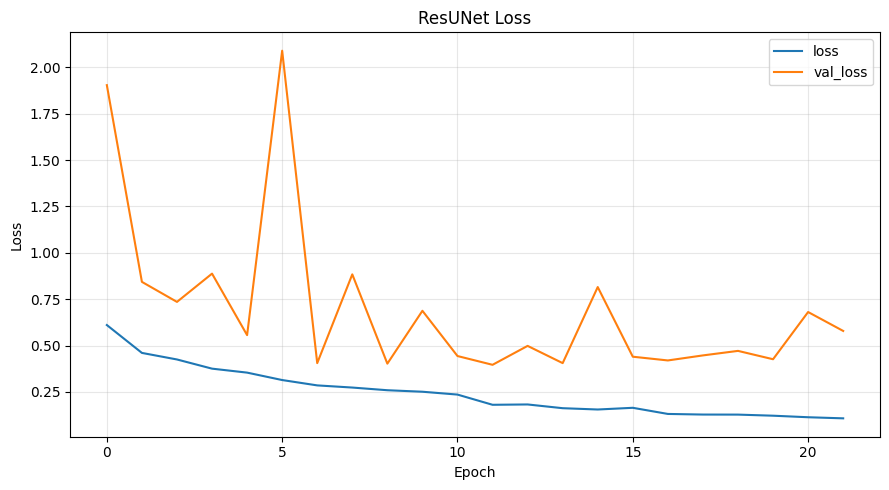

Saved: /raid/home/dgx1725/warwick_qu_resunet_outputs/training_loss.png


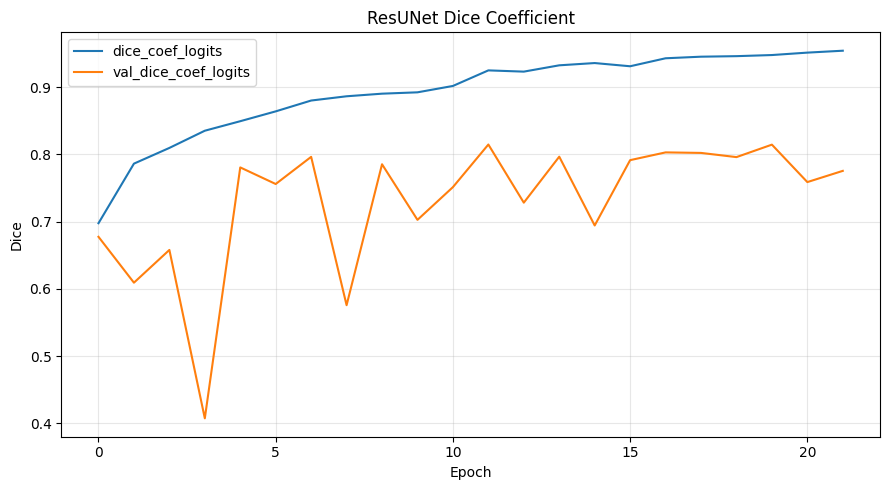

Saved: /raid/home/dgx1725/warwick_qu_resunet_outputs/training_dice.png


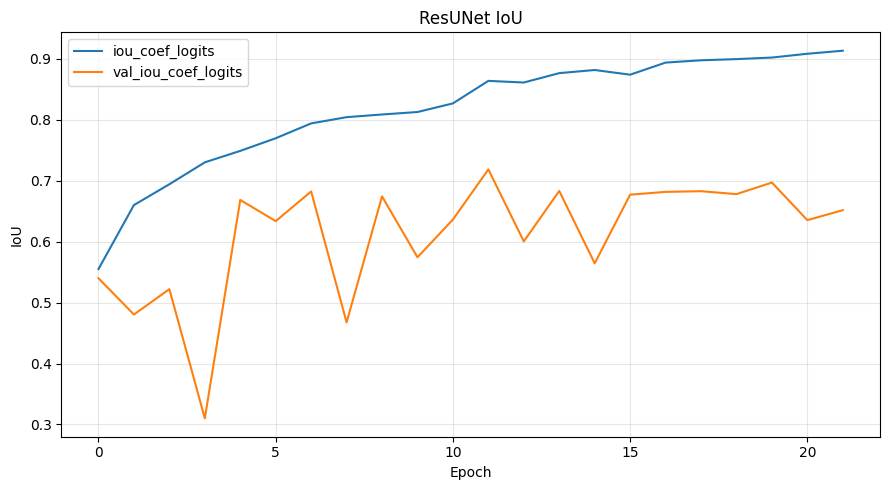

Saved: /raid/home/dgx1725/warwick_qu_resunet_outputs/training_iou.png
Evaluation ground-truth source: /raid/home/dgx1725/Warwick_QU_Dataset_Binary_FIXED/test/mask


In [5]:
def plot_history(history_dict, keys, title, ylabel, output_name):
    plt.figure(figsize=(9, 5))
    plotted = False
    for key in keys:
        if key in history_dict:
            plt.plot(history_dict[key], label=key)
            plotted = True
    if not plotted:
        print("No matching history keys for:", keys)
        plt.close()
        return
    plt.title(title)
    plt.xlabel("Epoch")
    plt.ylabel(ylabel)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    path = os.path.join(OUTPUT_DIR, output_name)
    plt.savefig(path, dpi=160, bbox_inches="tight")
    plt.show()
    print("Saved:", path)

plot_history(history.history, ["loss", "val_loss"], "ResUNet Loss", "Loss", "training_loss.png")
plot_history(history.history, ["dice_coef_logits", "val_dice_coef_logits"], "ResUNet Dice Coefficient", "Dice", "training_dice.png")
plot_history(history.history, ["iou_coef_logits", "val_iou_coef_logits"], "ResUNet IoU", "IoU", "training_iou.png")

METRIC_COLUMNS = [
    "IoU", "Recall", "Precision", "Dice_Coefficient",
    "Boundary_F1", "Boundary_Recall", "Boundary_Precision"
]

def safe_divide(numerator, denominator):
    return float(numerator / denominator) if denominator else 0.0

def binary_segmentation_metrics(y_true, y_pred):
    """Seven pixel/boundary metrics for one boolean mask pair."""
    gt = np.asarray(y_true, dtype=bool)
    pred = np.asarray(y_pred, dtype=bool)

    tp = int(np.logical_and(gt, pred).sum())
    fp = int(np.logical_and(~gt, pred).sum())
    fn = int(np.logical_and(gt, ~pred).sum())
    union = tp + fp + fn

    precision = safe_divide(tp, tp + fp)
    recall = safe_divide(tp, tp + fn)
    iou = safe_divide(tp, union)
    dice = safe_divide(2 * tp, 2 * tp + fp + fn)

    # Derive 1-pixel contours from binary masks using morphology.
    gt_u8 = gt.astype(np.uint8)
    pred_u8 = pred.astype(np.uint8)
    erode_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    gt_eroded = cv2.erode(gt_u8, erode_kernel, iterations=1)
    pred_eroded = cv2.erode(pred_u8, erode_kernel, iterations=1)
    gt_boundary = (gt_u8 - gt_eroded).astype(bool)
    pred_boundary = (pred_u8 - pred_eroded).astype(bool)

    # A 5x5 elliptical kernel gives approximately 2-pixel matching tolerance.
    k = 2 * BOUNDARY_TOLERANCE_PX + 1
    tolerance_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
    gt_boundary_dilated = cv2.dilate(gt_boundary.astype(np.uint8), tolerance_kernel, iterations=1).astype(bool)
    pred_boundary_dilated = cv2.dilate(pred_boundary.astype(np.uint8), tolerance_kernel, iterations=1).astype(bool)

    matched_pred_boundary = int(np.logical_and(pred_boundary, gt_boundary_dilated).sum())
    matched_gt_boundary = int(np.logical_and(gt_boundary, pred_boundary_dilated).sum())
    boundary_precision = safe_divide(matched_pred_boundary, int(pred_boundary.sum()))
    boundary_recall = safe_divide(matched_gt_boundary, int(gt_boundary.sum()))
    boundary_f1 = safe_divide(2 * boundary_precision * boundary_recall,
                              boundary_precision + boundary_recall)

    return {
        "IoU": iou,
        "Recall": recall,
        "Precision": precision,
        "Dice_Coefficient": dice,
        "Boundary_F1": boundary_f1,
        "Boundary_Recall": boundary_recall,
        "Boundary_Precision": boundary_precision,
    }

# Make sure the evaluation is not accidentally using another boundary-mask folder.
print("Evaluation ground-truth source:", TEST_MASK_DIR)
assert "Boundary_Mask_GT" not in TEST_MASK_DIR

[001/016] testB_1.png | IoU=0.3354 | Recall=0.7938 | Precision=0.3674 | Dice_Coefficient=0.5023 | Boundary_F1=0.3534 | Boundary_Recall=0.7677 | Boundary_Precision=0.2295
[002/016] testB_10.png | IoU=0.6326 | Recall=0.7198 | Precision=0.8393 | Dice_Coefficient=0.7750 | Boundary_F1=0.3906 | Boundary_Recall=0.5709 | Boundary_Precision=0.2968
[003/016] testB_11.png | IoU=0.9556 | Recall=0.9836 | Precision=0.9710 | Dice_Coefficient=0.9773 | Boundary_F1=0.8314 | Boundary_Recall=0.8553 | Boundary_Precision=0.8087
[004/016] testB_12.png | IoU=0.8500 | Recall=0.9340 | Precision=0.9043 | Dice_Coefficient=0.9189 | Boundary_F1=0.4718 | Boundary_Recall=0.5440 | Boundary_Precision=0.4164
[005/016] testB_13.png | IoU=0.8215 | Recall=0.9503 | Precision=0.8584 | Dice_Coefficient=0.9020 | Boundary_F1=0.5857 | Boundary_Recall=0.6920 | Boundary_Precision=0.5076
[006/016] testB_14.png | IoU=0.3793 | Recall=0.6785 | Precision=0.4624 | Dice_Coefficient=0.5500 | Boundary_F1=0.1894 | Boundary_Recall=0.3154 | B

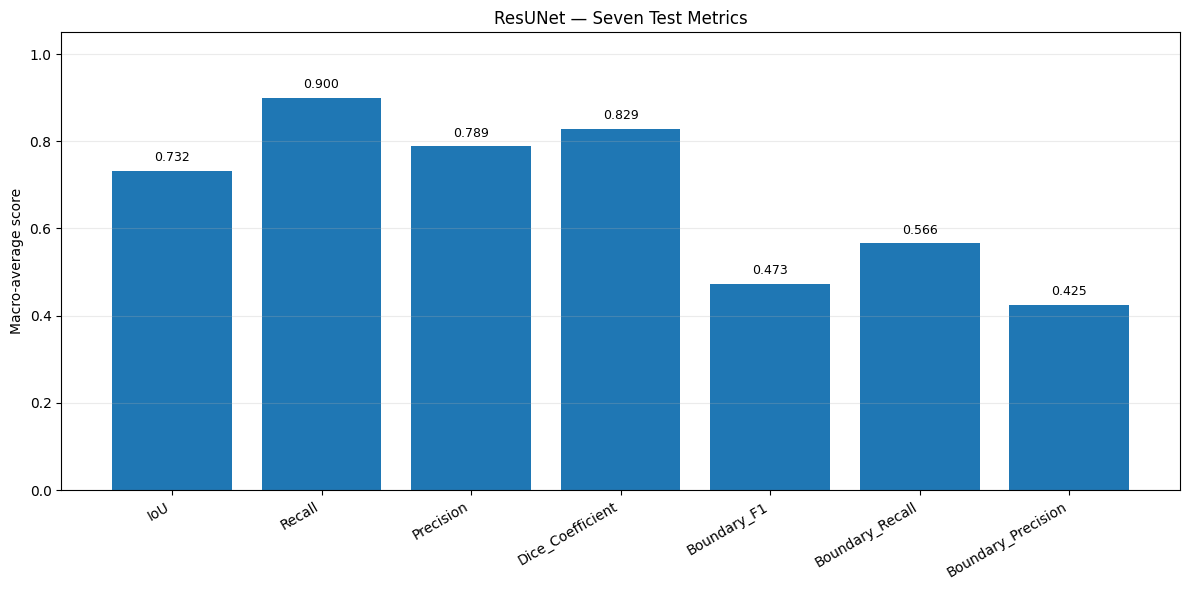

Saved: /raid/home/dgx1725/warwick_qu_resunet_outputs/summary_test_metrics_bar.png


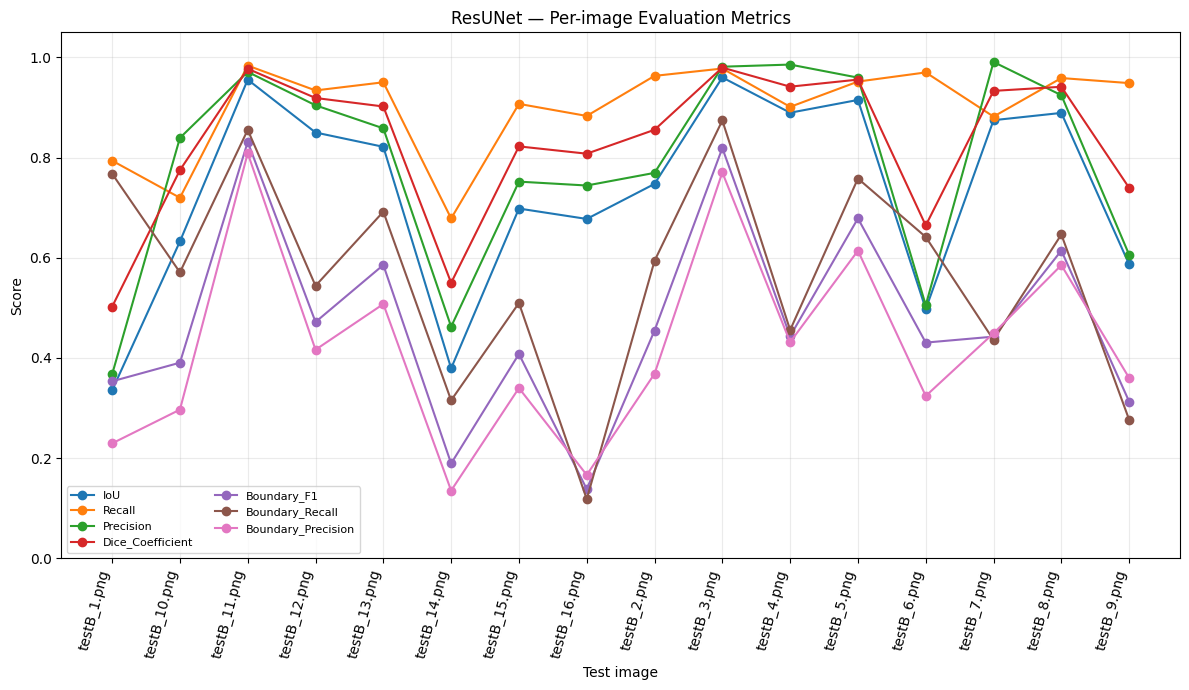

Saved: /raid/home/dgx1725/warwick_qu_resunet_outputs/per_image_test_metrics.png


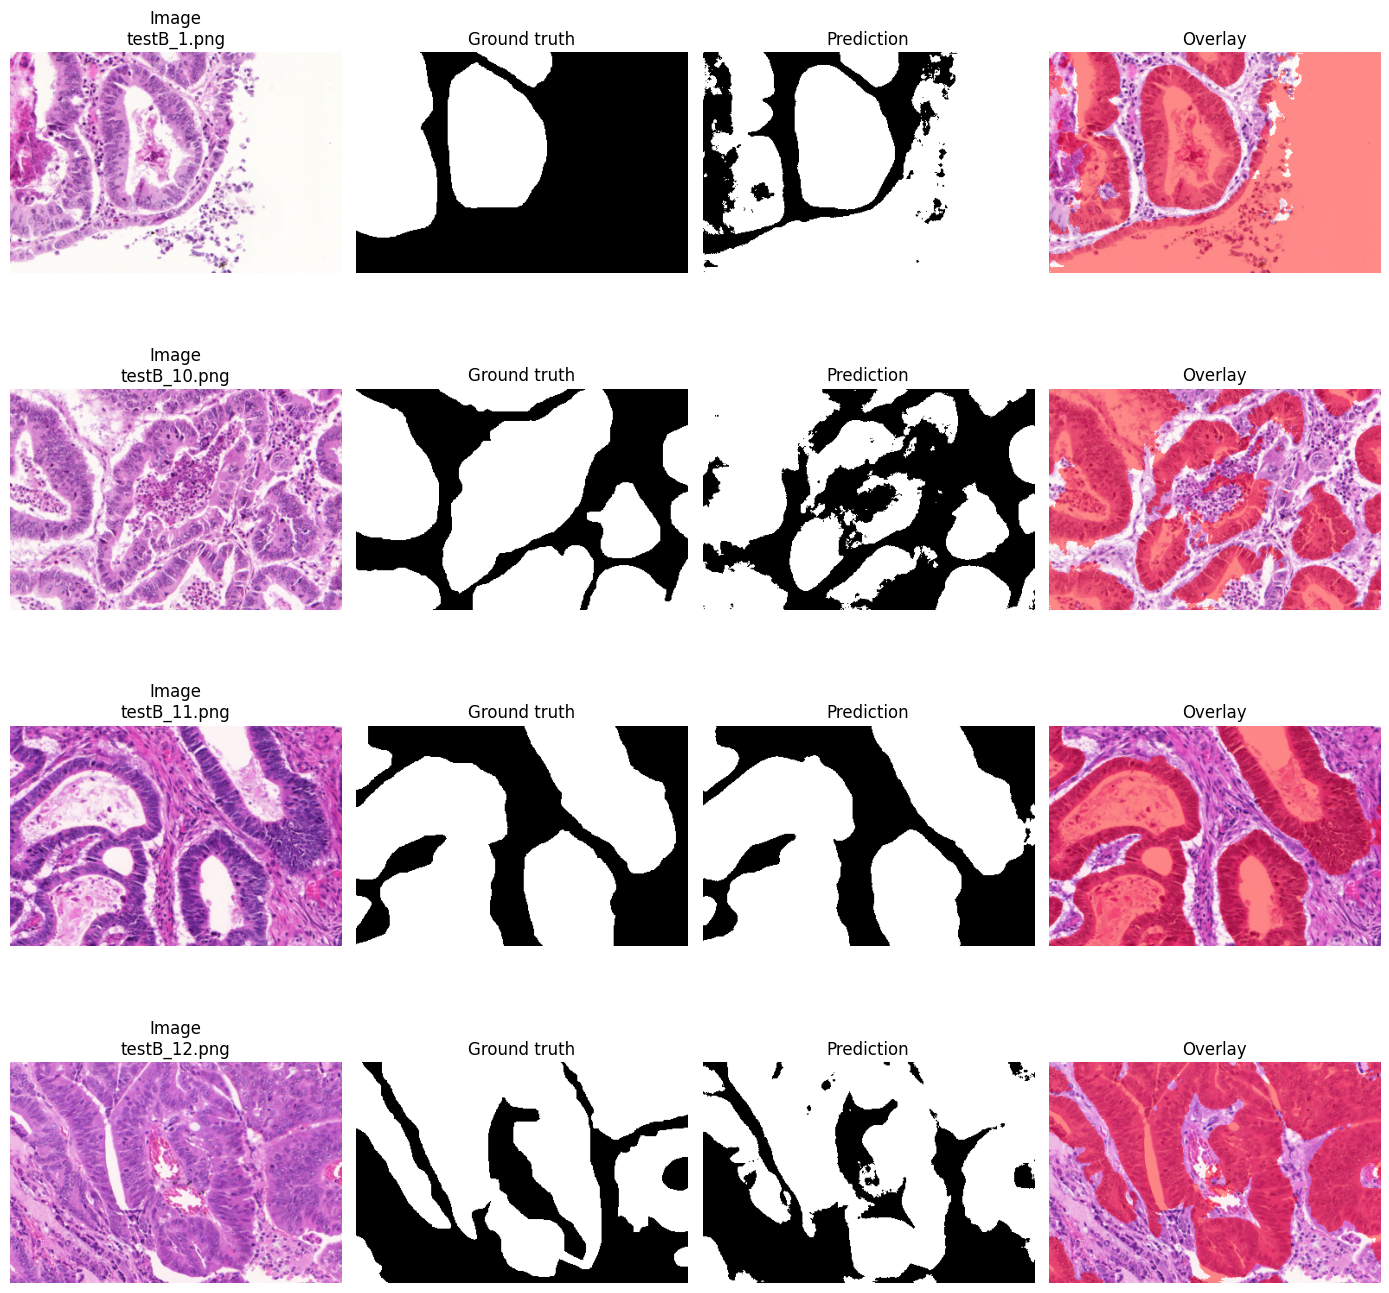

In [6]:
PREDICTION_DIR = os.path.join(OUTPUT_DIR, "predicted_masks")
PREVIEW_DIR = os.path.join(OUTPUT_DIR, "prediction_previews")
os.makedirs(PREDICTION_DIR, exist_ok=True)
os.makedirs(PREVIEW_DIR, exist_ok=True)

per_image_rows = []
preview_items = []

for idx, (image_path, mask_path) in enumerate(test_pairs, start=1):
    image, gt_mask = load_image_mask(image_path, mask_path)
    logits = model.predict(image[np.newaxis, ...], verbose=0)[0, ..., 0]
    probabilities = tf.math.sigmoid(logits).numpy()
    pred_mask = probabilities >= PREDICTION_THRESHOLD
    gt_binary = gt_mask[..., 0] >= 0.5

    metrics = binary_segmentation_metrics(gt_binary, pred_mask)
    row = {"image_name": Path(image_path).name, **metrics}
    per_image_rows.append(row)

    stem = Path(image_path).stem
    pred_u8 = (pred_mask.astype(np.uint8) * 255)
    cv2.imwrite(os.path.join(PREDICTION_DIR, f"{stem}_prediction.png"), pred_u8)

    # Save a visual comparison image: RGB original, GT, prediction, overlay.
    overlay = image.copy()
    overlay[pred_mask] = 0.55 * overlay[pred_mask] + 0.45 * np.array([1.0, 0.0, 0.0])
    if len(preview_items) < 8:
        preview_items.append((Path(image_path).name, image, gt_binary, pred_mask, overlay))

    preview_path = os.path.join(PREVIEW_DIR, f"{stem}_comparison.png")
    fig, axes = plt.subplots(1, 4, figsize=(14, 4))
    axes[0].imshow(image); axes[0].set_title("Image")
    axes[1].imshow(gt_binary, cmap="gray"); axes[1].set_title("Ground truth")
    axes[2].imshow(pred_mask, cmap="gray"); axes[2].set_title("Prediction")
    axes[3].imshow(np.clip(overlay, 0, 1)); axes[3].set_title("Prediction overlay")
    for ax in axes: ax.axis("off")
    fig.suptitle(Path(image_path).name)
    plt.tight_layout()
    fig.savefig(preview_path, dpi=140, bbox_inches="tight")
    plt.close(fig)

    print(
        f"[{idx:03d}/{len(test_pairs):03d}] {Path(image_path).name} | "
        + " | ".join(f"{name}={metrics[name]:.4f}" for name in METRIC_COLUMNS)
    )

if not per_image_rows:
    raise RuntimeError("Test split is empty; check the Warwick QU test folder.")

per_image_df = pd.DataFrame(per_image_rows)
per_image_csv = os.path.join(OUTPUT_DIR, "per_image_test_metrics.csv")
per_image_df.to_csv(per_image_csv, index=False)

summary_df = pd.DataFrame([{"metric": col, "macro_average": float(per_image_df[col].mean())} for col in METRIC_COLUMNS])
summary_csv = os.path.join(OUTPUT_DIR, "summary_test_metrics.csv")
summary_df.to_csv(summary_csv, index=False)

print("\n=== Macro-average test metrics (mean of per-image scores) ===")
for _, row in summary_df.iterrows():
    print(f"{row['metric']:<22}: {row['macro_average']:.4f}")
print("\nPer-image CSV:", per_image_csv)
print("Summary CSV :", summary_csv)
print("Predicted masks:", PREDICTION_DIR)
print("Prediction comparison plots:", PREVIEW_DIR)

plt.figure(figsize=(12, 6))
bar_values = summary_df["macro_average"].to_numpy(dtype=float)
bars = plt.bar(summary_df["metric"], bar_values)
plt.ylim(0, 1.05)
plt.ylabel("Macro-average score")
plt.title("ResUNet — Seven Test Metrics")
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.25)
for bar, val in zip(bars, bar_values):
    plt.text(bar.get_x() + bar.get_width() / 2, val + 0.015, f"{val:.3f}", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
bar_plot_path = os.path.join(OUTPUT_DIR, "summary_test_metrics_bar.png")
plt.savefig(bar_plot_path, dpi=180, bbox_inches="tight")
plt.show()
print("Saved:", bar_plot_path)

plt.figure(figsize=(max(12, len(per_image_df) * 0.45), 7))
for metric in METRIC_COLUMNS:
    plt.plot(per_image_df["image_name"], per_image_df[metric], marker="o", linewidth=1.5, label=metric)
plt.ylim(0, 1.05)
plt.ylabel("Score")
plt.xlabel("Test image")
plt.title("ResUNet — Per-image Evaluation Metrics")
plt.xticks(rotation=75, ha="right")
plt.grid(True, alpha=0.25)
plt.legend(ncol=2, fontsize=8)
plt.tight_layout()
per_image_plot_path = os.path.join(OUTPUT_DIR, "per_image_test_metrics.png")
plt.savefig(per_image_plot_path, dpi=180, bbox_inches="tight")
plt.show()
print("Saved:", per_image_plot_path)

n_show = min(4, len(preview_items))
if n_show:
    fig, axes = plt.subplots(n_show, 4, figsize=(14, 3.5 * n_show))
    if n_show == 1:
        axes = np.expand_dims(axes, axis=0)
    for i, (name, image, gt, pred, overlay) in enumerate(preview_items[:n_show]):
        axes[i, 0].imshow(image); axes[i, 0].set_title(f"Image\n{name}")
        axes[i, 1].imshow(gt, cmap="gray"); axes[i, 1].set_title("Ground truth")
        axes[i, 2].imshow(pred, cmap="gray"); axes[i, 2].set_title("Prediction")
        axes[i, 3].imshow(np.clip(overlay, 0, 1)); axes[i, 3].set_title("Overlay")
        for ax in axes[i]: ax.axis("off")
    plt.tight_layout()
    plt.show()

In [7]:
# Save predicted masks
PREDICTION_DIR = os.path.join(OUTPUT_DIR, "predicted_masks")
os.makedirs(PREDICTION_DIR, exist_ok=True)

for idx, (image_path, mask_path) in enumerate(val_pairs, start=1):
    image, _ = load_image_mask(image_path, mask_path)

    # Generate prediction
    logits = model.predict(image[np.newaxis, ...], verbose=0)[0, ..., 0]
    probabilities = tf.math.sigmoid(logits).numpy()
    pred_mask = probabilities >= PREDICTION_THRESHOLD

    # Convert mask to a black-and-white PNG (0 or 255)
    pred_mask_uint8 = (pred_mask.astype(np.uint8) * 255)

    # Save predicted mask
    filename = f"{Path(image_path).stem}_prediction.png"
    save_path = os.path.join(PREDICTION_DIR, filename)

    if not cv2.imwrite(save_path, pred_mask_uint8):
        raise IOError(f"Failed to save predicted mask: {save_path}")

    print(f"[{idx}/{len(val_pairs)}] Saved: {save_path}")

print(f"\nAll predicted masks saved in:\n{PREDICTION_DIR}")

[1/16] Saved: /raid/home/dgx1725/warwick_qu_resunet_outputs/predicted_masks/testA_1_prediction.png
[2/16] Saved: /raid/home/dgx1725/warwick_qu_resunet_outputs/predicted_masks/testA_10_prediction.png
[3/16] Saved: /raid/home/dgx1725/warwick_qu_resunet_outputs/predicted_masks/testA_11_prediction.png
[4/16] Saved: /raid/home/dgx1725/warwick_qu_resunet_outputs/predicted_masks/testA_12_prediction.png
[5/16] Saved: /raid/home/dgx1725/warwick_qu_resunet_outputs/predicted_masks/testA_13_prediction.png
[6/16] Saved: /raid/home/dgx1725/warwick_qu_resunet_outputs/predicted_masks/testA_14_prediction.png
[7/16] Saved: /raid/home/dgx1725/warwick_qu_resunet_outputs/predicted_masks/testA_15_prediction.png
[8/16] Saved: /raid/home/dgx1725/warwick_qu_resunet_outputs/predicted_masks/testA_16_prediction.png
[9/16] Saved: /raid/home/dgx1725/warwick_qu_resunet_outputs/predicted_masks/testA_2_prediction.png
[10/16] Saved: /raid/home/dgx1725/warwick_qu_resunet_outputs/predicted_masks/testA_3_prediction.png
[1